In [ ]:

# 1. Import Libraries
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [ ]:

# 2. Prepare Dataset
emails = [
    "free offer now",
    "win free prize",
    "claim your free gift",
    "win money today",
    "free discount offer",
    "congratulations you won a prize",
    "get free coupons now",
    "urgent claim your reward",
    "meeting at noon",
    "project report today",
    "team meeting schedule",
    "send the project file",
    "lecture starts tomorrow",
    "please review the report",
    "class meeting today",
    "submit your assignment",
    "team project discussion",
    "see you at the office",
    "free prize winner",
    "important project update"
]

labels = [
    "spam", "spam", "spam", "spam", "spam",
    "spam", "spam", "spam",
    "ham", "ham", "ham", "ham", "ham",
    "ham", "ham", "ham", "ham", "ham",
    "spam", "ham"
]

In [ ]:

# 3. Split Data
X_train, X_test, y_train, y_test = train_test_split(
    emails,
    labels,
    test_size=0.3,
    random_state=42,
    stratify=labels
)

In [ ]:

# 4. Create Naive Bayes Model
model = make_pipeline(
    CountVectorizer(),
    MultinomialNB(alpha=1.0)
)

In [ ]:

# 5. Train the Model
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [ ]:

# 6. Test a New Email
new_email = ["free prize offer"]

prediction = model.predict(new_email)
probabilities = model.predict_proba(new_email)

print("\nNew Email:", new_email[0])
print("Prediction:", prediction[0])

print("\nPrediction Probabilities:")

for class_name, probability in zip(model.classes_, probabilities[0]):
    print(class_name, ":", round(probability * 100, 2), "%")


New Email: free prize offer
Prediction: spam

Prediction Probabilities:
ham : 1.98 %
spam : 98.02 %


In [ ]:

# 7. Evaluate the Model
predictions = model.predict(X_test)

accuracy = accuracy_score(y_test, predictions)

print("\nAccuracy:", round(accuracy * 100, 2), "%")

print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, predictions, labels=["spam", "ham"])
print(cm)

print("\nClassification Report:")
print(classification_report(y_test, predictions, zero_division=0))


Accuracy: 66.67 %

Confusion Matrix:
[[2 1]
 [1 2]]

Classification Report:
              precision    recall  f1-score   support

         ham       0.67      0.67      0.67         3
        spam       0.67      0.67      0.67         3

    accuracy                           0.67         6
   macro avg       0.67      0.67      0.67         6
weighted avg       0.67      0.67      0.67         6



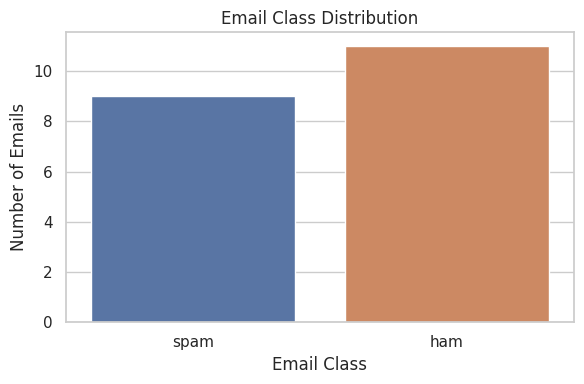

In [ ]:

# 8. Data Visualization
# ==========================================

sns.set_theme(style="whitegrid")


# Plot 1: Class Distribution
plt.figure(figsize=(6, 4))

sns.countplot(x=labels, hue=labels, legend=False)

plt.title("Email Class Distribution")
plt.xlabel("Email Class")
plt.ylabel("Number of Emails")
plt.tight_layout()
plt.show()

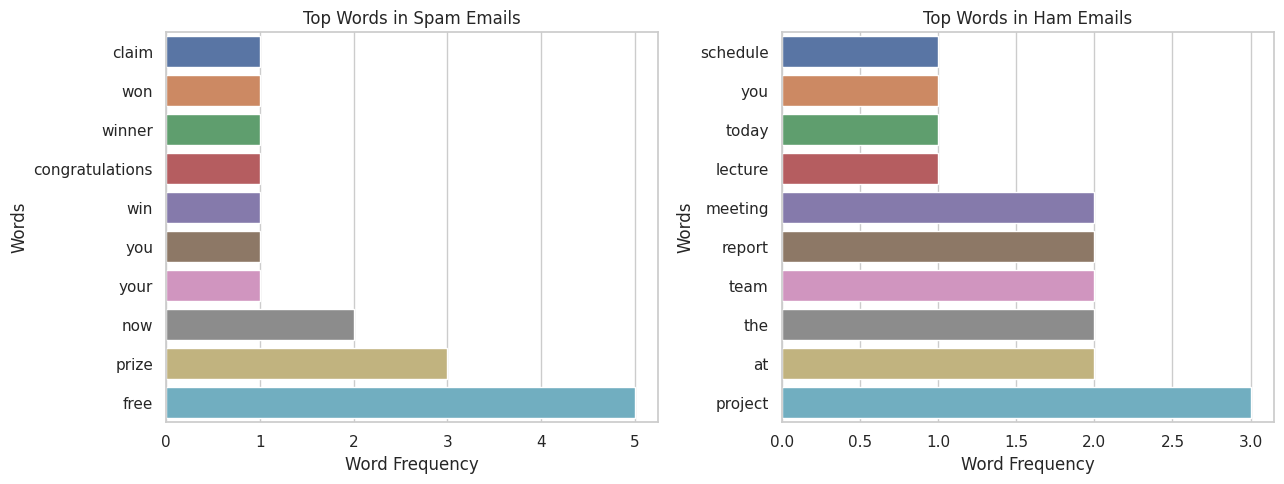

In [ ]:

# Plot 2: Word Frequency in Each Class

vectorizer = model.named_steps["countvectorizer"]

X_train_counts = vectorizer.transform(X_train)
feature_names = vectorizer.get_feature_names_out()

y_train_array = np.array(y_train)

spam_counts = np.asarray(
    X_train_counts[y_train_array == "spam"].sum(axis=0)
).flatten()

ham_counts = np.asarray(
    X_train_counts[y_train_array == "ham"].sum(axis=0)
).flatten()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, counts, class_name in zip(
    axes,
    [spam_counts, ham_counts],
    ["Spam", "Ham"]
):
    top_indices = np.argsort(counts)[-10:]

    sns.barplot(
        x=counts[top_indices],
        y=feature_names[top_indices],
        hue=feature_names[top_indices],
        legend=False,
        ax=ax
    )

    ax.set_title(f"Top Words in {class_name} Emails")
    ax.set_xlabel("Word Frequency")
    ax.set_ylabel("Words")

plt.tight_layout()
plt.show()

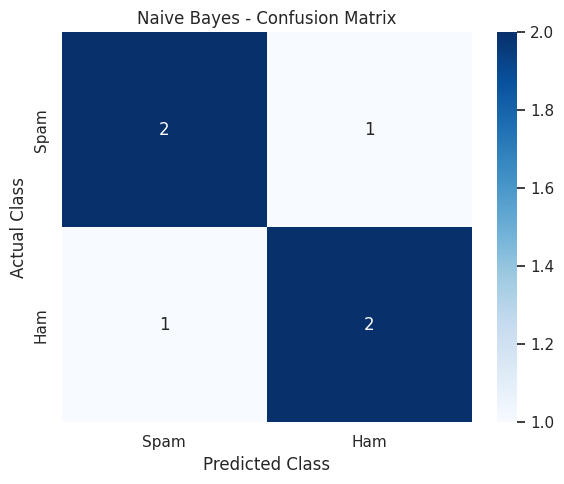

In [ ]:

# Plot 3: Confusion Matrix Heatmap

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Spam", "Ham"],
    yticklabels=["Spam", "Ham"]
)

plt.title("Naive Bayes - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

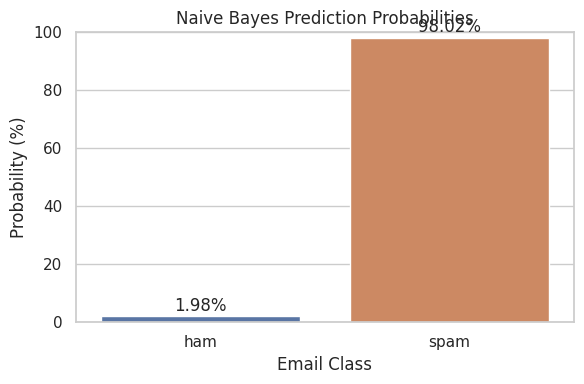

In [ ]:

# Plot 4: Prediction Probabilities

plt.figure(figsize=(6, 4))

sns.barplot(
    x=model.classes_,
    y=probabilities[0] * 100,
    hue=model.classes_,
    legend=False
)

plt.title("Naive Bayes Prediction Probabilities")
plt.xlabel("Email Class")
plt.ylabel("Probability (%)")
plt.ylim(0, 100)

for i, value in enumerate(probabilities[0] * 100):
    plt.text(i, value + 2, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

In [ ]:

# 9. Test Multiple New Emails

test_emails = [
    "win free money",
    "project meeting today",
    "claim your free prize",
    "please send the report"
]

print("\nTesting New Emails:")

for email in test_emails:
    result = model.predict([email])
    print(email, "---->", result[0])


Testing New Emails:
win free money ----> spam
project meeting today ----> ham
claim your free prize ----> spam
please send the report ----> ham
